# 🎙️ AI Voice Assistant: NLP & Speech Processing

A voice assistant that **listens**, **understands** what you want using NLP, **acts**, and **talks back**.
This notebook walks through the whole pipeline with real outputs: training data, text preprocessing, an intent classifier
(TF-IDF + Logistic Regression), evaluation, slot extraction, the skills (time, calculator, notes, search...), and the
voice (speech-to-text / text-to-speech) part.

```
 voice / text ──► Speech-to-Text ──► Preprocessing ──► Intent classifier ──► confident? ──► Slot extraction ──► Skill ──► reply (text + voice)
                                                      (TF-IDF + LogReg)         │ no
                                                                                └──► "Sorry, I did not understand"
```

**Contents**
1. Setup
2. Training data
3. Text preprocessing
4. Intent classifier
5. Evaluation on unseen phrases
6. Confidence threshold
7. Slot extraction
8. Skills (actions)
9. Full pipeline demo
10. Voice mode (run locally)
11. Web interface
12. Summary, limitations and future work

> The notebook is self-contained. Browser/app actions run in **dry-run mode** by default, so they only print what they *would* do.

## 1. Setup

In [1]:
# Install once if needed (remove the # to run):
# !pip install scikit-learn pandas matplotlib pyjokes wikipedia SpeechRecognition pyttsx3 sounddevice

import re, ast, json, math, random, operator, subprocess, webbrowser, warnings
import datetime as dt
from pathlib import Path
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)
print("Libraries loaded")

Libraries loaded


## 2. Training data
Each intent (what the user wants) has example phrases. The classifier learns from them.
More and more varied phrases give better accuracy.

15 intents, 133 training phrases


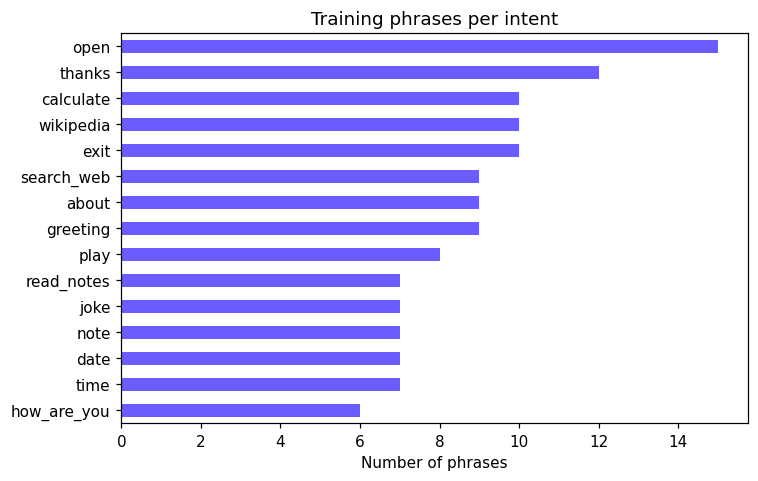

In [2]:
INTENTS = {
    "greeting": [
        "hello",
        "hi",
        "hey assistant",
        "good morning",
        "good evening",
        "hey there",
        "salam",
        "assalam o alaikum",
        "hi assistant"
    ],
    "how_are_you": [
        "how are you",
        "how are you doing",
        "how is it going",
        "are you okay",
        "how do you do",
        "how are you today"
    ],
    "about": [
        "who are you",
        "what is your name",
        "tell me about yourself",
        "what can you do",
        "help",
        "what are your features",
        "show commands",
        "help me",
        "what are you"
    ],
    "thanks": [
        "thank you",
        "thanks a lot",
        "thanks",
        "thank you so much",
        "that was helpful",
        "great thanks",
        "thanks for the help",
        "thank you for your help",
        "thanks assistant",
        "much appreciated",
        "thank you assistant",
        "thanks buddy"
    ],
    "time": [
        "what time is it",
        "tell me the time",
        "current time",
        "what's the time now",
        "time please",
        "do you know the time",
        "what is the time"
    ],
    "date": [
        "what is today's date",
        "what day is it today",
        "tell me the date",
        "today's date",
        "which day is today",
        "what's the date",
        "what is the date today"
    ],
    "search_web": [
        "search python tutorials on google",
        "google machine learning courses",
        "look up best laptops",
        "search for cheap flights",
        "find pizza recipes online",
        "search the web for news",
        "google weather in lahore",
        "search for data science jobs",
        "search data analyst salary"
    ],
    "wikipedia": [
        "who is albert einstein",
        "tell me about python programming",
        "what is machine learning",
        "wikipedia artificial intelligence",
        "explain neural networks",
        "who was quaid e azam",
        "what is photosynthesis",
        "tell me about pakistan",
        "what is deep learning",
        "who is elon musk"
    ],
    "open": [
        "open youtube",
        "open google",
        "open github",
        "go to facebook",
        "open linkedin",
        "open kaggle",
        "take me to wikipedia",
        "open notepad",
        "open calculator",
        "launch paint",
        "start notepad",
        "open command prompt",
        "open file explorer",
        "launch calculator",
        "open gmail"
    ],
    "play": [
        "play despacito on youtube",
        "play some music",
        "play imran khan songs",
        "youtube search cooking videos",
        "play lofi music",
        "play naat on youtube",
        "play arijit singh songs",
        "play a song"
    ],
    "joke": [
        "tell me a joke",
        "make me laugh",
        "say something funny",
        "joke please",
        "i want to hear a joke",
        "do you know any jokes",
        "tell a funny joke"
    ],
    "note": [
        "take a note buy milk",
        "write a note call ali",
        "note down meeting at five",
        "remember to submit assignment",
        "save a note study for exam",
        "make a note submit report",
        "take a note"
    ],
    "read_notes": [
        "read my notes",
        "show my notes",
        "what are my notes",
        "read notes",
        "list my notes",
        "what did i note",
        "show notes"
    ],
    "calculate": [
        "calculate 5 plus 3",
        "what is 12 times 4",
        "10 divided by 2",
        "what is 7 minus 2",
        "calculate 15 into 3",
        "compute 20 plus 30",
        "how much is 9 times 9",
        "what is 100 divided by 4",
        "calculate 8 minus 3",
        "25 plus 17"
    ],
    "exit": [
        "exit",
        "goodbye",
        "bye",
        "stop",
        "quit",
        "see you later",
        "shut down assistant",
        "good night",
        "stop listening",
        "bye bye"
    ]
}

counts = pd.Series({k: len(v) for k, v in INTENTS.items()}).sort_values()
print(f"{len(INTENTS)} intents, {counts.sum()} training phrases")

counts.plot(kind="barh", figsize=(7, 4.5), color="#6a5cff")
plt.title("Training phrases per intent")
plt.xlabel("Number of phrases")
plt.tight_layout()
plt.show()

## 3. Text preprocessing
Lowercase, remove punctuation, and replace every number with one token (`num`), so "5 plus 3" and "12 plus 4" look the same
to the model and it learns the *pattern* of a calculation.

In [3]:
def preprocess(text: str) -> str:
    """Lowercase, replace numbers with one token, remove punctuation."""
    text = text.lower().strip()
    text = re.sub(r"\d+(\.\d+)?", " num ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for s in ["What's the TIME?!", "Calculate 12 times 4", "5 plus 3", "Search   Python   tutorials!!!"]:
    print(f"{s!r:36} -> {preprocess(s)!r}")

"What's the TIME?!"                  -> "what's the time"
'Calculate 12 times 4'               -> 'calculate num times num'
'5 plus 3'                           -> 'num plus num'
'Search   Python   tutorials!!!'     -> 'search python tutorials'


## 4. Intent classifier
* **TF-IDF** converts a sentence into numbers: a word gets a high weight if it is frequent in the sentence but rare across all
  training phrases ("calculate" is informative, "the" is not). `ngram_range=(1, 2)` also uses word pairs such as "what time".
* **Logistic Regression** turns those numbers into a probability for every intent. The highest probability is the **confidence**.

In [4]:
THRESHOLD = 0.35   # below this confidence the assistant says it did not understand

def make_model():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(C=20, max_iter=2000))

class IntentClassifier:
    def __init__(self, intents):
        self.X, self.y = [], []
        for tag, phrases in intents.items():
            for p in phrases:
                self.X.append(preprocess(p))
                self.y.append(tag)
        self.model = make_model().fit(self.X, self.y)

    def predict(self, text):
        """Return (intent, confidence)."""
        probs = self.model.predict_proba([preprocess(text)])[0]
        i = probs.argmax()
        return str(self.model.classes_[i]), float(probs[i])

clf = IntentClassifier(INTENTS)
cv = cross_val_score(make_model(), clf.X, clf.y, cv=3)
print(f"Trained on {len(clf.X)} phrases")
print(f"3-fold cross-validation accuracy on the training phrases: {cv.mean():.1%}")

Trained on 133 phrases
3-fold cross-validation accuracy on the training phrases: 75.9%


**What did the model learn?** The most influential words for each intent:

In [5]:
vec = clf.model.named_steps["tfidfvectorizer"]
lr = clf.model.named_steps["logisticregression"]
terms = np.array(vec.get_feature_names_out())

rows = [(intent, ", ".join(terms[np.argsort(lr.coef_[i])[-4:][::-1]])) for i, intent in enumerate(lr.classes_)]
display(pd.DataFrame(rows, columns=["intent", "most influential words"]))

,intent,most influential words
0,about,"help, show commands, commands, what"
1,calculate,"num, is num, calculate, calculate num"
2,date,"date, today, the date, day"
3,exit,"bye, stop, exit, quit"
4,greeting,"hi, hello, salam, hey"
5,how_are_you,"how, are you, you, how are"
6,joke,"joke, funny, laugh, me laugh"
7,note,"note, submit, take note, take"
8,open,"open, launch, notepad, calculator"
9,play,"play, youtube, music, songs"


## 5. Evaluation on unseen phrases
These 24 phrases are **not** in the training data. A case passes only if the intent is correct **and** the confidence is above the threshold.
> This is a small, hand-written test set, so treat it as a sanity check, not a benchmark.

In [6]:
TEST_CASES = [
    ("hello there", "greeting"), ("good morning assistant", "greeting"),
    ("what time is it right now", "time"), ("can you tell me the current time", "time"),
    ("what is the date today", "date"), ("tell me today's date", "date"),
    ("search for python courses on google", "search_web"), ("google best phones", "search_web"),
    ("who is cristiano ronaldo", "wikipedia"), ("tell me about the moon", "wikipedia"),
    ("open whatsapp", "open"), ("launch notepad", "open"),
    ("play shape of you", "play"), ("play some naat on youtube", "play"),
    ("tell me something funny", "joke"), ("make me laugh please", "joke"),
    ("take a note call mom tomorrow", "note"), ("read my notes please", "read_notes"),
    ("calculate 45 plus 55", "calculate"), ("what is 9 times 7", "calculate"),
    ("thanks for the help", "thanks"), ("how are you doing today", "how_are_you"),
    ("goodbye assistant", "exit"), ("what can you do", "about"),
]

rows = []
for text, expected in TEST_CASES:
    got, conf = clf.predict(text)
    ok = got == expected and conf >= THRESHOLD
    rows.append((text, expected, got, round(conf, 2), "✅ PASS" if ok else "❌ FAIL"))

df = pd.DataFrame(rows, columns=["phrase", "expected", "predicted", "confidence", "result"])
display(df)

passed = (df["result"] == "✅ PASS").sum()
print(f"\nIntent accuracy on unseen phrases: {passed}/{len(df)} = {passed / len(df):.0%}")

,phrase,expected,predicted,confidence,result
0,hello there,greeting,greeting,0.85,✅ PASS
1,good morning assistant,greeting,greeting,0.89,✅ PASS
2,what time is it right now,time,time,0.84,✅ PASS
3,can you tell me the current time,time,time,0.63,✅ PASS
4,what is the date today,date,date,0.93,✅ PASS
5,tell me today's date,date,date,0.83,✅ PASS
6,search for python courses on google,search_web,search_web,0.93,✅ PASS
7,google best phones,search_web,search_web,0.64,✅ PASS
8,who is cristiano ronaldo,wikipedia,wikipedia,0.86,✅ PASS
9,tell me about the moon,wikipedia,wikipedia,0.46,✅ PASS



Intent accuracy on unseen phrases: 24/24 = 100%


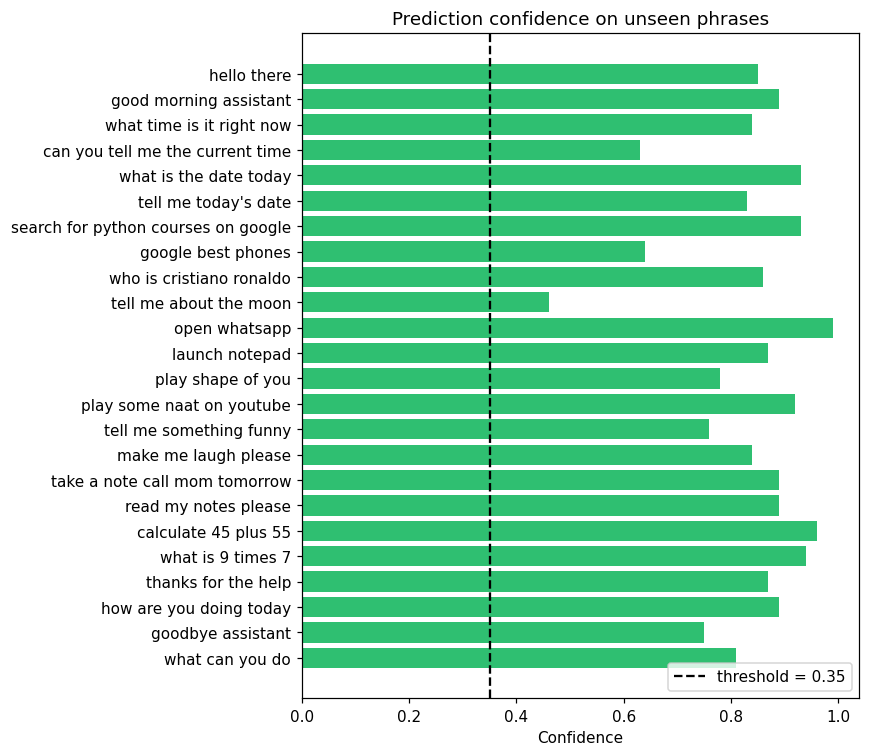

In [7]:
# Confidence of every test prediction
fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#2fbf71" if r == "✅ PASS" else "#ff5f7e" for r in df["result"]]
ax.barh(df["phrase"], df["confidence"], color=colors)
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"threshold = {THRESHOLD}")
ax.invert_yaxis()
ax.set_xlabel("Confidence")
ax.set_title("Prediction confidence on unseen phrases")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

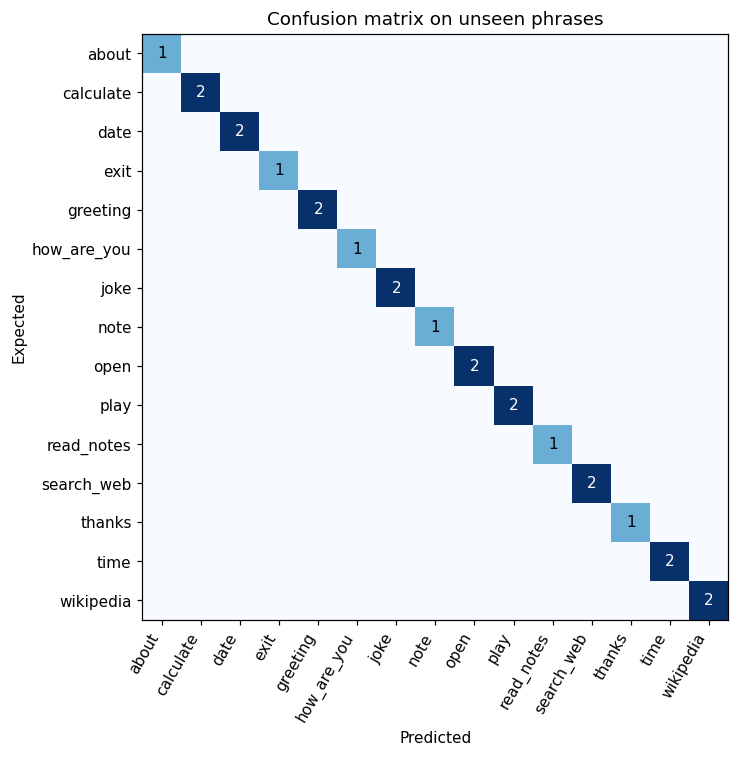

In [8]:
# Confusion matrix (rows = expected intent, columns = predicted intent)
labels = sorted(INTENTS)
cm = confusion_matrix(df["expected"], df["predicted"], labels=labels)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("Expected")
ax.set_title("Confusion matrix on unseen phrases")
plt.tight_layout()
plt.show()

## 6. Confidence threshold
A classifier must always pick *some* intent, even for nonsense. Rejecting low-confidence predictions is better than running the wrong action.

In [9]:
nonsense = ["blah qwerty zzz", "the quick brown fox", "asdfgh jkl", "purple monkey dishwasher"]
rows = []
for t in nonsense:
    intent, conf = clf.predict(t)
    rows.append((t, intent, round(conf, 2), "understood" if conf >= THRESHOLD else "rejected (asks again)"))
display(pd.DataFrame(rows, columns=["input", "best guess", "confidence", "decision"]))

,input,best guess,confidence,decision
0,blah qwerty zzz,open,0.12,rejected (asks again)
1,the quick brown fox,time,0.26,rejected (asks again)
2,asdfgh jkl,open,0.12,rejected (asks again)
3,purple monkey dishwasher,open,0.12,rejected (asks again)


## 7. Slot extraction
The intent says *what* to do; **slots** say *with what*. Simple rules extract the useful part of the sentence.

In [10]:
_FILLER_START = {"search", "for", "google", "on", "the", "web", "look", "up", "find", "online", "please", "about"}

def extract_search_query(text):
    words = text.lower().strip().split()
    while words and words[0] in _FILLER_START:
        words.pop(0)
    q = " ".join(words)
    return re.sub(r"\s+(on google|online|on the web|on the internet)$", "", q).strip()

def extract_topic(text):
    q = text.lower().strip()
    lead = r"^(who is|who was|who are|what is|what are|what was|tell me about|tell me more about|explain|wikipedia|search wikipedia for|define|a|an|the)\s+"
    while True:
        new = re.sub(lead, "", q)
        if new == q:
            return q
        q = new

def extract_open_target(text):
    m = re.match(r"^(open|launch|start|go to|take me to)\s+(the\s+)?(.+?)(\s+(app|website|site|application))?$", text.lower().strip())
    return m.group(3).strip() if m else ""

def extract_play_query(text):
    m = re.match(r"^(play|youtube search|search youtube for)\s*(.*?)(\s+on youtube)?$", text.lower().strip())
    q = m.group(2).strip() if m else ""
    return q if q and q not in {"a song", "some music", "music"} else "lofi music"

def extract_note(text):
    t = text.lower().strip()
    t = re.sub(r"^(take a note|write a note|note down|remember to|save a note|make a note)\s*(that|to)?\s*", "", t)
    return t.strip()

examples = [
    ("search python tutorials on google", extract_search_query),
    ("who is albert einstein",            extract_topic),
    ("open the notepad app",              extract_open_target),
    ("play despacito on youtube",         extract_play_query),
    ("take a note buy milk",              extract_note),
]
display(pd.DataFrame([(s, f.__name__, f(s)) for s, f in examples], columns=["sentence", "function", "extracted slot"]))

,sentence,function,extracted slot
0,search python tutorials on google,extract_search_query,python tutorials
1,who is albert einstein,extract_topic,albert einstein
2,open the notepad app,extract_open_target,notepad
3,play despacito on youtube,extract_play_query,despacito
4,take a note buy milk,extract_note,buy milk


## 8. Skills (actions)
`handle(intent, text)` runs the right action. Notes on safety:
* The calculator evaluates the expression with Python's `ast` module and allows only numbers and `+ - * /`. It never uses `eval()`, so no code can be injected.
* `DRY_RUN = True` means browser and app actions only print what they would do. Set it to `False` on your own computer to really open pages and apps.

In [11]:
DRY_RUN = True            # False: really open the browser / Windows apps
NOTES = Path("notes/notes.txt")
ACTIONS = []              # what the last command did (shown in the demo)

SITES = {"youtube": "youtube.com", "google": "google.com", "github": "github.com", "facebook": "facebook.com",
         "linkedin": "linkedin.com", "kaggle": "kaggle.com", "wikipedia": "wikipedia.org", "gmail": "mail.google.com",
         "twitter": "x.com"}
APPS = {"notepad": "notepad", "calculator": "calc", "paint": "mspaint", "command prompt": "cmd", "file explorer": "explorer"}
JOKES = ["Why do programmers prefer dark mode? Because light attracts bugs.",
         "Why did the data scientist break up with the graph? It had too many outliers.",
         "I told my computer I needed a break, and it said: no problem, I'll go to sleep."]

def open_url(url):
    if DRY_RUN:
        ACTIONS.append(f"(dry run) would open {url}")
    else:
        webbrowser.open(url)

# ---------- safe calculator ----------
_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv}

def _eval(node):
    if isinstance(node, ast.Expression):
        return _eval(node.body)
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _OPS:
        return _OPS[type(node.op)](_eval(node.left), _eval(node.right))
    if isinstance(node, ast.UnaryOp) and isinstance(node.op, ast.USub):
        return -_eval(node.operand)
    raise ValueError("unsupported expression")

def calculate(text):
    t = text.lower()
    for word, sym in [("multiplied by", "*"), ("divided by", "/"), ("plus", "+"), ("minus", "-"),
                      ("times", "*"), ("into", "*"), ("over", "/"), (" x ", "*")]:
        t = t.replace(word, f" {sym} ")
    tokens = re.findall(r"\d+\.?\d*|[+\-*/]", t)
    if len(tokens) < 3:
        return "Sorry, I could not find a calculation. Try: calculate 12 times 4."
    try:
        result = _eval(ast.parse(" ".join(tokens), mode="eval"))
    except ZeroDivisionError:
        return "I cannot divide by zero."
    except Exception:
        return "Sorry, I could not calculate that."
    result = int(result) if float(result).is_integer() else round(result, 4)
    return f"The answer is {result}."

# ---------- other skills ----------
def greeting():
    h = dt.datetime.now().hour
    return f"Good {'morning' if h < 12 else 'afternoon' if h < 18 else 'evening'}! How can I help you?"

def open_target(text):
    target = extract_open_target(text)
    if not target:
        return "What should I open?"
    if target in APPS:
        if DRY_RUN:
            ACTIONS.append(f"(dry run) would start the app '{APPS[target]}'")
        else:
            subprocess.Popen(APPS[target], shell=True)
        return f"Opening {target}."
    if target in SITES:
        open_url("https://" + SITES[target])
        return f"Opening {target}."
    open_url("https://www.google.com/search?q=" + quote_plus(target))
    return f"I did not know {target}, so I searched Google for it."

def wikipedia_answer(text):
    topic = extract_topic(text)
    try:
        import wikipedia
        return wikipedia.summary(topic, sentences=2, auto_suggest=False)
    except ImportError:
        return "The wikipedia package is not installed. Run: pip install wikipedia"
    except Exception as e:
        return f"I could not get a Wikipedia answer for {topic} ({type(e).__name__})."

def joke():
    try:
        import pyjokes
        return pyjokes.get_joke()
    except Exception:
        return random.choice(JOKES)

def save_note(text):
    note = extract_note(text)
    if not note:
        return "What should I note? Say: take a note, followed by your note."
    NOTES.parent.mkdir(exist_ok=True)
    with open(NOTES, "a", encoding="utf-8") as f:
        f.write(f"{dt.datetime.now():%Y-%m-%d %H:%M}  {note}\n")
    return f"Noted: {note}."

def read_notes():
    if not NOTES.exists():
        return "You have no notes yet."
    lines = NOTES.read_text(encoding="utf-8").strip().splitlines()[-3:]
    return "Your latest notes: " + ". ".join(l[17:].strip() for l in lines)

ABOUT = ("I am a voice assistant. I can tell the time and date, search Google, answer questions from Wikipedia, "
         "open websites and apps, play YouTube, calculate, tell jokes and take notes.")

def handle(intent, text):
    """Run the skill for an intent. Returns (reply, should_exit)."""
    if intent == "exit":        return "Goodbye! Have a great day.", True
    if intent == "greeting":    return greeting(), False
    if intent == "how_are_you": return "I am doing great, thank you for asking!", False
    if intent == "about":       return ABOUT, False
    if intent == "thanks":      return "You are welcome!", False
    if intent == "time":        return f"It is {dt.datetime.now():%I:%M %p}.", False
    if intent == "date":        return f"Today is {dt.datetime.now():%A, %d %B %Y}.", False
    if intent == "search_web":
        q = extract_search_query(text)
        open_url("https://www.google.com/search?q=" + quote_plus(q))
        return f"Here is what I found on Google for {q}.", False
    if intent == "wikipedia":   return wikipedia_answer(text), False
    if intent == "open":        return open_target(text), False
    if intent == "play":
        q = extract_play_query(text)
        open_url("https://www.youtube.com/results?search_query=" + quote_plus(q))
        return f"Playing {q} on YouTube.", False
    if intent == "joke":        return joke(), False
    if intent == "note":        return save_note(text), False
    if intent == "read_notes":  return read_notes(), False
    if intent == "calculate":   return calculate(text), False
    return "Sorry, I cannot do that yet.", False

print("Skills ready:", ", ".join(sorted(INTENTS)))

Skills ready: about, calculate, date, exit, greeting, how_are_you, joke, note, open, play, read_notes, search_web, thanks, time, wikipedia


## 9. Full pipeline demo
`assistant_reply()` combines everything: intent classification, the confidence threshold, slot extraction and the skill.
Below is a simulated conversation (typed commands, as if the speech had already been converted to text).

In [12]:
def assistant_reply(text):
    text = text.strip().lower()
    intent, conf = clf.predict(text)
    if conf < THRESHOLD:
        return {"intent": intent, "confidence": conf, "reply": "Sorry, I did not understand that. Say help to see what I can do.", "exit": False}
    reply, stop = handle(intent, text)
    return {"intent": intent, "confidence": conf, "reply": reply, "exit": stop}

NOTES.unlink(missing_ok=True)      # start the demo with an empty notes file

conversation = [
    "hello", "what time is it", "what is today's date",
    "calculate 12 times 4", "what is 100 divided by 4", "5 divided by 0",
    "tell me a joke", "take a note submit the project report", "take a note buy milk", "read my notes",
    "search python tutorials on google", "open youtube", "open notepad", "play lofi music on youtube",
    "how are you", "thanks for the help", "blah qwerty zzz", "bye",
]

for command in conversation:
    ACTIONS.clear()
    r = assistant_reply(command)
    print(f"🧑 You: {command}")
    print(f"🤖 [{r['intent']}, confidence {r['confidence']:.2f}] {r['reply']}")
    for a in ACTIONS:
        print(f"   ↳ {a}")
    print()
    if r["exit"]:
        break

🧑 You: hello
🤖 [greeting, confidence 0.82] Good evening! How can I help you?

🧑 You: what time is it
🤖 [time, confidence 0.85] It is 09:46 PM.

🧑 You: what is today's date
🤖 [date, confidence 0.92] Today is Monday, 12 October 2026.

🧑 You: calculate 12 times 4
🤖 [calculate, confidence 0.95] The answer is 48.

🧑 You: what is 100 divided by 4
🤖 [calculate, confidence 0.94] The answer is 25.

🧑 You: 5 divided by 0
🤖 [calculate, confidence 0.93] I cannot divide by zero.

🧑 You: tell me a joke
🤖 [joke, confidence 0.85] I told my computer I needed a break, and it said: no problem, I'll go to sleep.

🧑 You: take a note submit the project report
🤖 [note, confidence 0.91] Noted: submit the project report.

🧑 You: take a note buy milk
🤖 [note, confidence 0.88] Noted: buy milk.

🧑 You: read my notes
🤖 [read_notes, confidence 0.94] Your latest notes: submit the project report. buy milk

🧑 You: search python tutorials on google
🤖 [search_web, confidence 0.87] Here is what I found on Google for pyth

> **Wikipedia questions** ("who is Albert Einstein") need the `wikipedia` package and an internet connection. Try them on your own computer.

## 10. Voice mode (run locally)
Speech-to-text uses the free Google Web Speech API (internet needed). The recorder measures background noise, starts when you speak
and stops after about one second of silence. Text-to-speech uses `pyttsx3` (works offline).

This part needs a microphone, so it is **off** here. On your own computer: `pip install SpeechRecognition sounddevice pyttsx3`,
set `RUN_VOICE = True` and run the cell. Say **"exit"** to stop.

In [13]:
RUN_VOICE = False     # set True on your own computer (microphone + internet needed)

def speak(text):
    """Print the reply and speak it aloud (offline)."""
    print(f"Assistant: {text}")
    try:
        import pyttsx3
        engine = pyttsx3.init()          # new engine each time avoids a known hang in notebooks
        engine.setProperty("rate", 170)
        engine.say(text)
        engine.runAndWait()
        engine.stop()
    except Exception:
        pass

def _rms(data):
    return float(np.sqrt(np.mean(data.astype(np.float32) ** 2)))

def listen(timeout=6, phrase_limit=10):
    """Record until the speaker stops, then convert speech to text ('' if nothing understood)."""
    import sounddevice as sd
    import speech_recognition as sr

    rate, step = 16000, 0.1
    block = int(rate * step)
    frames, started, waited, silent = [], False, 0.0, 0.0
    with sd.InputStream(samplerate=rate, channels=1, dtype="int16", blocksize=block) as stream:
        print("Listening...")
        noise = [_rms(stream.read(block)[0]) for _ in range(5)]        # 0.5 s noise calibration
        threshold = max(400.0, 3 * float(np.mean(noise)))
        while True:
            data = stream.read(block)[0]
            loud = _rms(data) > threshold
            if not started:
                if loud:
                    started = True
                    frames.append(data)
                else:
                    waited += step
                    if waited >= timeout:
                        return ""
            else:
                frames.append(data)
                silent = 0.0 if loud else silent + step
                if silent >= 1.0 or len(frames) * step >= phrase_limit:
                    break
    audio = sr.AudioData(np.concatenate(frames).tobytes(), rate, 2)
    try:
        return sr.Recognizer().recognize_google(audio).lower()
    except sr.UnknownValueError:
        return ""
    except sr.RequestError:
        print("(Speech service unreachable - check your internet connection)")
        return ""

def run_voice_assistant():
    speak("Hello! I am your voice assistant. Say exit to stop.")
    while True:
        text = listen()
        if not text:
            continue
        print(f"You: {text}")
        r = assistant_reply(text)
        speak(r["reply"])
        if r["exit"]:
            break

if RUN_VOICE:
    run_voice_assistant()
else:
    print("Voice mode is off. Set RUN_VOICE = True on a computer with a microphone to try it.")

Voice mode is off. Set RUN_VOICE = True on a computer with a microphone to try it.


## 11. Web interface
The full project also includes an animated web interface (FastAPI + HTML/CSS/JavaScript): an orb that reacts while listening, thinking
and speaking, a chat history with the detected intent and confidence, and a mic button.

```bash
pip install fastapi uvicorn
python web_app.py        # opens http://127.0.0.1:8000  (use Chrome or Edge and allow the microphone)
```

<!-- Add your screenshot: put it in docs/demo.png and uncomment the next line
![Web UI](docs/demo.png)
-->

See the project repository for `web_app.py`, `static/index.html` and `docs/CODE_EXPLANATION.md`.

### Project files
```
ai-voice-assistant/
├── main.py                      terminal app (voice or text mode)
├── web_app.py                   FastAPI server for the web interface
├── static/index.html            web UI: animated orb, chat, mic button
├── assistant/
│   ├── nlp.py                   preprocessing, intent classifier, slot extraction
│   ├── skills.py                the action behind every intent
│   └── speech.py                speech-to-text and text-to-speech
├── data/intents.json            training phrases
├── tests/test_intents.py        evaluation on unseen phrases
├── notebooks/AI_Voice_Assistant.ipynb   this notebook
└── docs/CODE_EXPLANATION.md     file-by-file explanation
```

### Backend code (`web_app.py`)
The web interface reuses the same NLP and skills code as this notebook. The server has three endpoints:
`GET /` (the page), `POST /command` (text in, reply + intent + confidence out) and `POST /listen` (records with the Python microphone as a fallback).

```python
"""Web interface for the AI Voice Assistant.

Run:  python web_app.py      (opens http://127.0.0.1:8000 in your browser)
"""
import socket
import threading
import webbrowser
from pathlib import Path

import uvicorn
from fastapi import FastAPI, HTTPException
from fastapi.responses import FileResponse
from pydantic import BaseModel

from assistant.nlp import THRESHOLD, IntentClassifier
from assistant.skills import handle
from assistant.speech import listen

HOST = "127.0.0.1"
BASE = Path(__file__).resolve().parent      # works no matter which folder you run it from
app = FastAPI(title="AI Voice Assistant")
clf = IntentClassifier()


class Command(BaseModel):
    text: str


def process(text: str) -> dict:
    """Same pipeline as main.py: intent classification -> skill -> reply."""
    text = text.strip().lower()
    intent, conf = clf.predict(text)
    stop = False
    if conf < THRESHOLD:
        reply = "Sorry, I did not understand that. Say help to see what I can do."
    else:
        try:
            reply, stop = handle(intent, text)
        except Exception as e:  # never crash the server
            reply = f"Sorry, something went wrong ({type(e).__name__})."
    return {"text": text, "reply": reply, "intent": intent, "confidence": round(conf, 2),
            "understood": conf >= THRESHOLD, "exit": stop}


@app.get("/")
def index():
    return FileResponse(BASE / "static" / "index.html")


@app.post("/command")
def command(cmd: Command):
    if not cmd.text.strip():
        raise HTTPException(status_code=400, detail="Empty command")
    return process(cmd.text[:500])


@app.post("/listen")
def listen_route():
    """Fallback for browsers without speech recognition: record with the Python microphone code."""
    try:
        return {"text": listen()}
    except (ImportError, OSError) as e:
        raise HTTPException(status_code=503, detail=str(e))


def free_port(start: int = 8000) -> int:
    """First free port from `start` upwards (in case 8000 is already in use)."""
    for port in range(start, start + 20):
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            if s.connect_ex((HOST, port)) != 0:
                return port
    return start


if __name__ == "__main__":
    port = free_port()
    url = f"http://{HOST}:{port}"
    print(f"\nAI Voice Assistant is running at {url}\nPress Ctrl+C in this window to stop it.\n")
    threading.Timer(1.5, lambda: webbrowser.open(url)).start()
    uvicorn.run(app, host=HOST, port=port)
```

The page itself (`static/index.html`) is plain HTML, CSS and JavaScript. It uses the browser's speech recognition and speech synthesis,
and changes the orb animation with a state (`idle`, `listening`, `thinking`, `speaking`).

## 12. Summary, limitations and future work

In [14]:
print(f"Intents ............................ {len(INTENTS)}")
print(f"Training phrases ................... {len(clf.X)}")
print(f"Cross-validation accuracy .......... {cv.mean():.1%}")
print(f"Unseen-phrase accuracy ............. {passed}/{len(df)} ({passed / len(df):.0%})")
print(f"Confidence threshold ............... {THRESHOLD}")

Intents ............................ 15
Training phrases ................... 133
Cross-validation accuracy .......... 75.9%
Unseen-phrase accuracy ............. 24/24 (100%)
Confidence threshold ............... 0.35


**Reading the two accuracy numbers:** cross-validation (about 76%) is lower than the unseen-phrase test (100%) because each fold trains on only two thirds of an already small dataset, so it is a pessimistic estimate. The unseen test has just 24 phrases written by the author, so it is optimistic. Real accuracy is probably somewhere in between, and it improves with more training phrases.

**Limitations**
* Small training set (the unseen test set is also small and written by the author), so unusual wording may be misunderstood.
* English only; speech recognition needs an internet connection and depends on the microphone and background noise.
* Opening desktop apps is Windows-specific.

**Future work**
Offline speech recognition (Vosk), a wake word ("Hey assistant"), more skills (weather, reminders, email), an LLM fallback
(Claude API or local Ollama) for open-ended questions, and Urdu support.

---
**Author:** Muhammad Abdullah · [GitHub](https://github.com/MuhammadAbdullahIkram) · [LinkedIn](https://linkedin.com/in/muhammad-abdullah-394288242)